# Chronological strategy validation · actual IEX minutes

후보를 미리 고정하고, 과거 검증 구간으로 선택한 전략을 다음 구간에서 평가합니다. **개발 이력 → 선택용 검증 → 이후 평가** 순서를 지키고, 마지막 42거래일을 이번 선택 과정에서 제외합니다.

이 자료는 이전 전체 기간 분석에도 쓰였으므로 완전히 미관측인 외부 holdout이라고 부르지 않습니다. 실제 미관측 성과는 앞으로의 paper 기록으로 검증해야 합니다. 이 노트북은 주문을 전송하거나 paper 전략을 변경하지 않습니다.

In [1]:
import importlib.util
import json
import os
import sys
from pathlib import Path

candidates = [p for parent in (Path.cwd(), *Path.cwd().parents) for p in (parent, parent / "jane/quant")]
REPO_DIR = next((p for p in candidates if (p / "quantcore/research/walk_forward.py").exists()), None)
if REPO_DIR is None:
    raise RuntimeError("QuantCore 프로젝트 또는 notebooks 폴더에서 실행하세요.")
missing = [m for m in ["numpy", "pandas", "matplotlib", "IPython"] if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError(f"현재 커널에 {missing}가 없습니다. QuantCore (Python 3.12) 커널을 선택하세요. Python: {sys.executable}")
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_DIR / "artifacts/matplotlib"))
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("Project:", REPO_DIR)
print("Python:", sys.executable)

Project: /Users/kanghyeon/Desktop/Project/jane/quant
Python: /Users/kanghyeon/Desktop/Project/jane/quant/.venv/bin/python


In [2]:
RUN_RESEARCH_AGAIN = False
if RUN_RESEARCH_AGAIN:
    from quantcore.research.walk_forward import run_validation
    report = run_validation(REPO_DIR)
else:
    report = json.loads((REPO_DIR / "docs/walk_forward_results.json").read_text())
metadata, results = report["metadata"], report["results"]
labels = {"selected_oos":"Selected by prior validation", "fixed_momentum_60":"Fixed Momentum60", "always_active_slots":"Always active / same risk", "selected_double_cost":"Selected / double costs"}
print("Executed:",metadata["executed_at"])
print("Source:",metadata["source"],"| snapshot:",metadata["snapshot_id"])
print("OOS:",metadata["oos_period"],metadata["oos_sessions"],"sessions")
display(pd.DataFrame({labels[k]:v["metrics"] for k,v in results.items()}).T[["total_return","final_equity","max_drawdown","annualized_volatility","average_gross_weight","fill_events"]].style.format({"total_return":"{:.2%}","final_equity":"${:,.2f}","max_drawdown":"{:.2%}","annualized_volatility":"{:.2%}","average_gross_weight":"{:.2%}","fill_events":"{:.0f}"}))

Executed: 2026-11-25T14:09:23.371883+00:00
Source: Alpaca IEX frozen actual minutes | snapshot: 20261125T013853Z
OOS: ['2026-05-28', '2026-11-24'] 126 sessions


,total_return,final_equity,max_drawdown,annualized_volatility,average_gross_weight,fill_events
Selected by prior validation,-3.82%,"$96,180.52",-9.88%,12.75%,31.65%,133
Fixed Momentum60,-3.51%,"$96,486.17",-7.37%,8.79%,36.92%,134
Always active / same risk,4.73%,"$104,727.66",-6.88%,9.83%,39.94%,86
Selected / double costs,-4.01%,"$95,985.70",-10.06%,12.77%,31.68%,131


,fold,kind,training,validation,test,selected,available_at,test_return
0,1,walk_forward,2025-11-06 → 2026-03-26,2026-03-27 → 2026-05-27,2026-05-28 → 2026-07-28,momentum_40,2026-05-27T20:01:00+00:00,-2.54%
1,2,walk_forward,2025-11-06 → 2026-05-27,2026-05-28 → 2026-07-28,2026-07-29 → 2026-09-25,momentum_90,2026-07-28T20:01:00+00:00,1.20%
2,3,reserved_holdout,2025-11-06 → 2026-07-28,2026-07-29 → 2026-09-25,2026-09-28 → 2026-11-24,mean_reversion,2026-09-25T20:01:00+00:00,-2.48%


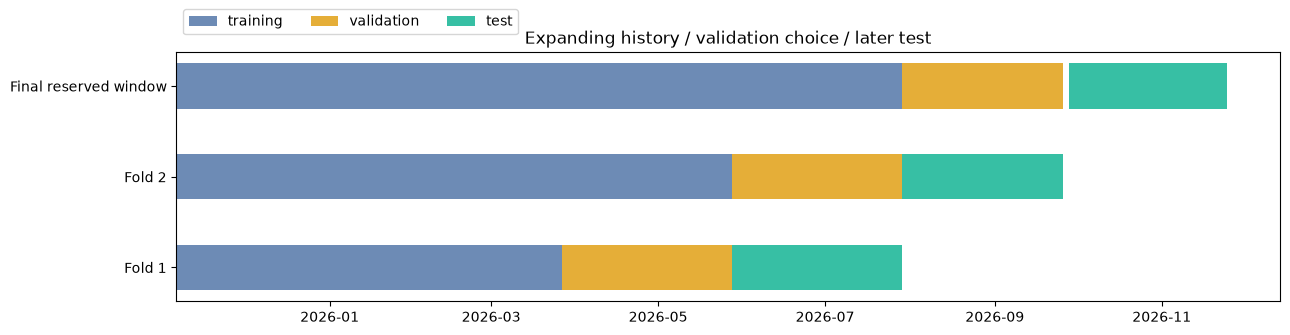

In [3]:
decisions = pd.DataFrame([{ "fold":d["fold"],"kind":d["kind"],"training":" → ".join(d["training"]),"validation":" → ".join(d["validation"]),"test":" → ".join(d["test"]),"selected":d["selected"],"available_at":d["selection_available_at"],"test_return":d["oos"]["selected_oos"]["total_return"]} for d in report["decisions"]])
display(decisions.style.format({"test_return":"{:.2%}"}))
fig, ax = plt.subplots(figsize=(13,3.5))
for i,d in enumerate(report["decisions"]):
    for key,color in [("training","#6d8bb5"),("validation","#e5ae38"),("test","#37bfa4")]:
        first,last = [pd.Timestamp(x) for x in d[key]]
        ax.barh(i,(last-first).days+1,left=mdates.date2num(first),color=color,label=key if i==0 else None,height=.5)
ax.set_yticks(range(len(decisions)),["Fold 1","Fold 2","Final reserved window"])
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left",bbox_to_anchor=(0,1.2),ncol=3)
ax.set_title("Expanding history / validation choice / later test")
fig.tight_layout()
plt.show()

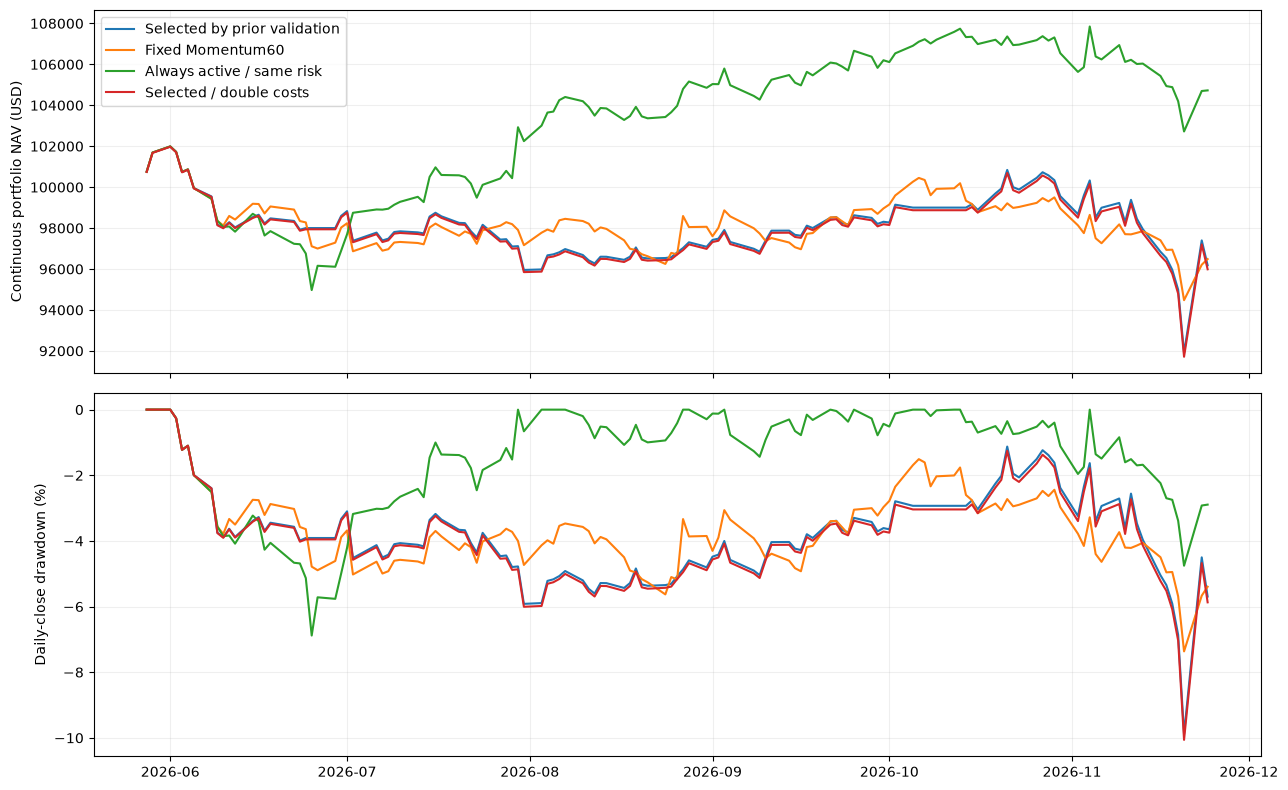

,min_cash,min_inventory,signal_before_fill,limit_respected,sessions,cash_inventory_nav_reconciled,split_events
Selected by prior validation,57106.98735330323158685914025,0,True,True,126,True,0
Fixed Momentum60,57757.84151385197627025986230,0,True,True,126,True,0
Always active / same risk,57027.43452122844595323666990,0,True,True,126,True,0
Selected / double costs,56912.17379379753309903842480,0,True,True,126,True,0


Paired sample uncertainty: {'method': 'paired circular 5-session block bootstrap; 2000 seeded samples', 'difference_total_return_95_interval': [-0.09183260792257296, 0.09178462160099454], 'scope': 'sample uncertainty only; no selection-bias or untouched-data guarantee'}
Training basis: fixed rule candidates have no fitted weights; expanding training history and subsequent validation select lookback/strategy
Classification basis: UNCLASSIFIED: current SEC metadata collected after this historical evaluation
• retrospective archive already observed in older reports; final reserve is not a genuinely unseen external holdout
• small selected five-instrument universe and one venue; historical revisions not archived as originally observed
• only two walk-forward test windows plus one reserved final window; no proof of stable profitability
• prior validation picks cannot inspect future test returns; ties follow the fixed candidate list
• classification/cost/thresholds were not optimized; modele

In [4]:
fig, axes = plt.subplots(2,1,figsize=(13,8),sharex=True)
for name,result in results.items():
    frame = pd.DataFrame(result["curve"])
    x = pd.to_datetime(frame.session)
    nav = np.r_[100000,frame.equity.to_numpy()]
    dd = nav / np.maximum.accumulate(nav)-1
    axes[0].plot(x,frame.equity,label=labels[name])
    axes[1].plot(x,dd[1:]*100,label=labels[name])
axes[0].set_ylabel("Continuous portfolio NAV (USD)")
axes[0].legend()
axes[1].set_ylabel("Daily-close drawdown (%)")
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
display(pd.DataFrame({labels[k]:v["audit"] for k,v in results.items()}).T)
print("Paired sample uncertainty:",report["paired_uncertainty"])
print("Training basis:",metadata["training_basis"])
print("Classification basis:",metadata["classification_basis"])
for limitation in metadata["limitations"]:
    print("•",limitation)

후보는 Momentum40/60/90과 Mean Reversion20입니다. 학습 가중치가 있는 모델이 아니라 고정 규칙이며, 과거 운용 이력 다음의 검증 구간 Sharpe로 규칙을 선택합니다.

일별 수익률을 서로 다른 가상 계좌에서 잘라 붙이지 않습니다. 선택된 규칙을 날짜별로 전달해 **126거래일 동안 하나의 현금·보유 원장**을 계속 실행합니다. 구간이 바뀌어도 자금·보유·낙폭 정지를 초기화하지 않습니다. 기본 전략과 상시 보유 기준에도 같은 리스크·거래 비용을 적용합니다.

현재 SEC 분류는 이 과거 평가 이후에 수집됐으므로 소급 사용하지 않고 미분류 그룹 40% 한도를 유지했습니다. 비용 2배 실험은 선택을 다시 최적화하지 않고 같은 선택 일정을 평가합니다. 결과가 나빠도 그대로 보고합니다.